# **09. Decile, Gain, Lift Analysis**

#### **Introduction**

This notebook evaluates a predictive model developed using the **Bank Telemarketing dataset** containing 45,211 customer records. The model's performance is evaluated using **Gain, Lift, and Decile Analysis** to determine how effectively it identifies customers who are more likely to subscribe to a term deposit. The analysis helps in ranking customers based on their predicted response and identifying the most promising customer segments for targeted marketing.


### **Project Structure**

**1. Decile Analysis** → Divide customers into 10 groups based on predicted probability/score and compare actual response rates.
* Decile response rate
* Number of responders
* Cumulative responders

**2. Lift Analysis** → Show how much better each decile performs compared with the overall response rate.
* Lift by decile
* Lift chart

**3. Gain Analysis** → Show the cumulative percentage of responders captured as you move down the ranked customer list.
* Cumulative gain 
* Gain chart

**4. Uncertainty Analysis** → Add statistical uncertainty to your key decile/lift/gain/business metrics.
* Bootstrap confidence intervals for response rate/lift/gain

**5. Business Impact** → Translate the model's targeting performance into business value.
* Baseline strategy
* Top-10% strategy
* Net profit
* Profit per contacted customer
* Profit-efficiency lift
* ROI comparison

---

In [1]:
# Import Libraries
import sys
sys.path.append("..")
from src.utilis import *

from scipy import stats
import time
from pathlib import Path
import pickle
import joblib


In [2]:
# Define path for preprocessed data and models file
parent_path = Path.cwd().parent
processed_file_path = parent_path.joinpath("models", "baseline_data.joblib")
fine_tuned_file_path = parent_path.joinpath("models", "tuned_models_data.joblib")

display_md("**Loading Preprocessed data & best models...**")
try:
    processed_data = joblib.load(processed_file_path)
    tuned_model_pipeline = joblib.load(fine_tuned_file_path)

    X_train, X_test = processed_data['X_train'], processed_data['X_test']
    y_train, y_test = processed_data['y_train'], processed_data['y_test']
    numeric_columns, categorical_columns = processed_data['numeric_columns'], processed_data['categorical_columns']
    baseline_pipeline = processed_data['best_pipeline']
    tuned_pipeline, calibrated_pipeline = tuned_model_pipeline['best_tuned_pipeline'], tuned_model_pipeline['best_calibrated_pipeline']

except Exception as e:
    display_md(f"**Loading Error: {e}**")


**Loading Preprocessed data & best models...**

In [3]:
display_md("**Loading Actual & Predicted Values...**")
try:
    actual_values = y_test.values.tolist()
    predicted_values = tuned_pipeline.predict(X_test).tolist()
    predicted_proba = tuned_pipeline.predict_proba(X_test)[:, 1].tolist()

    df = pd.DataFrame([actual_values, predicted_values, predicted_proba]).T
    df.columns = ['actual_values', 'predicted_values', 'predicted_proba']
    display(df.head())
    
except Exception as e:
    print(f"Data Loading Error : {e}")
    

**Loading Actual & Predicted Values...**

,actual_values,predicted_values,predicted_proba
0,0.00,0.00,0.01
1,0.00,1.00,0.75
2,0.00,0.00,0.15
3,0.00,1.00,0.95
4,0.00,0.00,0.38


In [4]:
print(f"Actual Response Rate : {df['actual_values'].mean()*100:.1f}%")
print(f"Predicted Response Rate : {df['predicted_values'].mean()*100:.1f}%")
print(f"Predicted Probability Average : {df['predicted_proba'].mean()*100:.1f}%")


Actual Response Rate : 11.7%
Predicted Response Rate : 22.0%
Predicted Probability Average : 23.8%


## **1. Decile Analysis**

Decile analysis is a useful technique for evaluating how effectively a bank's telemarketing campaign identifies customers who are likely to subscribe to a term deposit or Which group of customers has the highest probability of subscribing?

we can rank customers based on their predicted subscription probability and divide them into __10 equal-sized groups (deciles)__.

**Objective of decile analysis**:
- The objective is to identify the top 10% or 20% of customers who have the highest probability of subscribing to a term deposit.This helps the bank prioritize customers for telemarketing calls.



decile,cumulative_population_percentage,customers,subscribers,conversion_rate,avg_probability
1,10%,"1,492",925,62.0%,92.2%
2,20%,"1,492",532,35.7%,71.7%
3,30%,"1,492",191,12.8%,41.1%
4,40%,"1,492",55,3.7%,18.2%
5,50%,"1,492",30,2.0%,7.8%
6,60%,"1,491",3,0.2%,3.6%
7,70%,"1,492",6,0.4%,1.8%
8,80%,"1,492",1,0.1%,0.8%
9,90%,"1,492",1,0.1%,0.3%
10,100%,"1,492",1,0.1%,0.1%


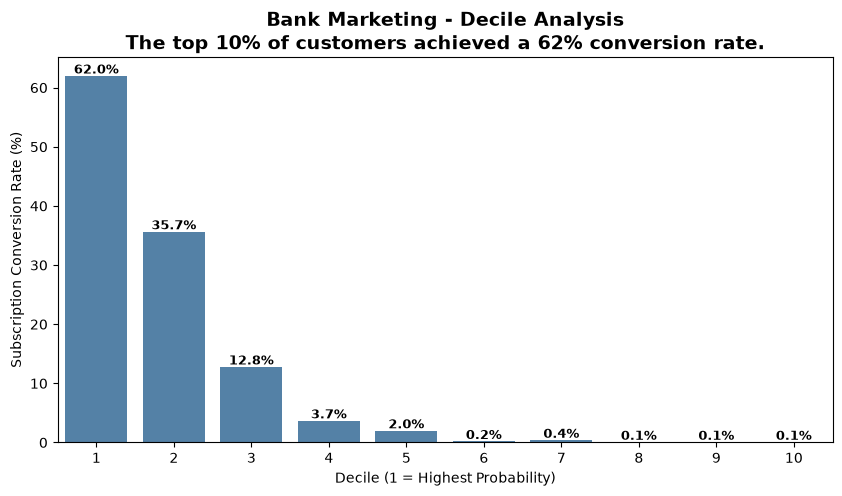

In [5]:
# Decile dataframe
decile_df = df[['actual_values', 'predicted_proba']].copy()

# Rank customers
decile_df = decile_df.sort_values(
    "predicted_proba",
    ascending=False
).reset_index(drop=True)

# Divide customers into 10 deciles (1 = highest customers)
decile_df["decile"] = pd.qcut(
    decile_df.index + 1,
    q=10,
    labels=range(1, 11)
)

# Calculate decile metrics
decile_table = decile_df.groupby("decile", observed=False).agg(
    customers=("actual_values", "count"),
    subscribers=("actual_values", "sum"),
    avg_probability=("predicted_proba", "mean")
).reset_index()

decile_table["conversion_rate"] = (
    decile_table["subscribers"] / decile_table["customers"] * 100
)


decile_table["cumulative_subscribers"] = (
    decile_table["subscribers"].cumsum()
)

total_subscribers = decile_table['subscribers'].sum()

# cumulative gain or cumulative conversion rate
decile_table["cumulative_gain"] = (
    decile_table["cumulative_subscribers"] /
    total_subscribers * 100
)

decile_table['population_percentage'] = (
    decile_table['customers']/
    decile_table['customers'].sum() * 100
)

decile_table['cumulative_population_percentage'] = (
    decile_table['population_percentage'].cumsum()
)

overall_rate = decile_df["actual_values"].mean()

decile_table["lift"] = (
    decile_table["conversion_rate"] / (overall_rate * 100)
)

decile_table['avg_probability'] = decile_table['avg_probability'].mul(100)

summary_ = decile_table[['decile', 'cumulative_population_percentage', 'customers', 'subscribers', 'conversion_rate', 'avg_probability']].round(1)
display(
    summary_.
    style
    .format({
        'cumulative_population_percentage':"{:.0f}%",
        'customers':"{:,.0f}",
        'subscribers':"{:,.0f}",
        'conversion_rate':"{:.1f}%",
        'avg_probability':"{:.1f}%"
    })
    .hide(axis='index')
)

# Visualize decile table

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=decile_table,
    x="decile",
    y="conversion_rate",
    color="steelblue"
)

for i, val in enumerate(decile_table['conversion_rate']):
    plt.text(
        x=i, y=val+2, 
        s=f"{val:.1f}%",
        fontdict={"size":9, "weight":"bold"},
        ha='center', va='top'
    )

plt.title("Bank Marketing - Decile Analysis\nThe top 10% of customers achieved a 62% conversion rate.", fontsize=14, fontweight='bold')
plt.xlabel("Decile (1 = Highest Probability)")
plt.ylabel("Subscription Conversion Rate (%)")

plt.show()



**Business interpretation**

The bank can use decile analysis to:

Target high-probability customers first.

Reduce unnecessary telemarketing calls.

Improve campaign conversion rates.

Allocate marketing resources efficiently.

Identify the most promising customer segments.

## **2. Gain Analysis**

Gain How many actual subscribers can we capture by targeting the top 10%, 20%, 30% of customers?

Formula,
Gain(x) = Number of subscriber in top x% / total number of subscribers


decile,cumulative_population_percentage,customers,subscribers,cumulative_subscribers,cumulative_gain
1,10%,"1,492",925.0,925.0,53.0%
2,20%,"1,492",532.0,"1,457.0",83.5%
3,30%,"1,492",191.0,"1,648.0",94.4%
4,40%,"1,492",55.0,"1,703.0",97.6%
5,50%,"1,492",30.0,"1,733.0",99.3%
6,60%,"1,491",3.0,"1,736.0",99.5%
7,70%,"1,492",6.0,"1,742.0",99.8%
8,80%,"1,492",1.0,"1,743.0",99.9%
9,90%,"1,492",1.0,"1,744.0",99.9%
10,100%,"1,492",1.0,"1,745.0",100.0%


**3rd decile the cumulative gain is 94.4% .That means, if we target top 30% customers, we will be able to capture 94.4% responders.We can acquire 94.4% of the potential subscribing customers by targeting only the top 30% of customers, potentially reducing telemarketing campaign costs by up to 70%.**

**The predictive model enables more targeted marketing campaigns, improves resource allocation, and reduces unnecessary customer contacts**

<Figure size 1000x500 with 0 Axes>

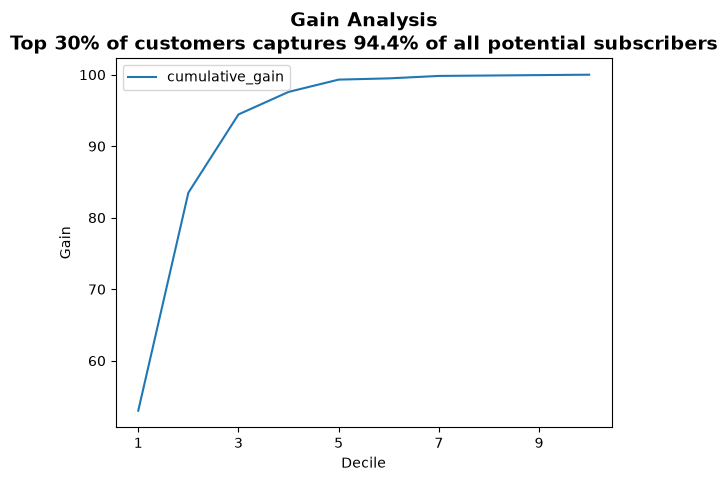

In [6]:
# Lift dataframe
gain_table = decile_table[[
    'decile', 'cumulative_population_percentage', 'customers', 'subscribers', 'cumulative_subscribers', 'cumulative_gain'
]]
display(
    gain_table.
    style.
    format({
        'customers':'{:,}',
        'cumulative_population_percentage':'{:.0f}%',
        'subscribers':'{:,}',
        'cumulative_subscribers':'{:,}',
        'cumulative_gain':'{:.1f}%'
    }).
    hide(axis='index')
)

# Visualize the lift table
plt.figure(figsize=(10, 5))
gain_table.plot(
    x='decile',
    y='cumulative_gain'
)

plt.title("Gain Analysis\nTop 30% of customers captures 94.4% of all potential subscribers", fontsize=14, fontweight='bold')
plt.xlabel("Decile")
plt.ylabel("Gain")
display_md("**3rd decile the cumulative gain is 94.4% .That means, if we target top 30% customers, we will be able to capture 94.4% responders.We can acquire 94.4% of the potential subscribing customers by targeting only the top 30% of customers, potentially reducing telemarketing campaign costs by up to 70%.**")
display_md("**The predictive model enables more targeted marketing campaigns, improves resource allocation, and reduces unnecessary customer contacts**")
plt.show()


## **3. Lift Analysis**

Lift compares the model's response rate with the response rate obtained by randomly selecting customers. 
The Lift Analysis demonstrates that our predictive model performs significantly better than random customer selection.


Formula,

Lift(x) = Response rate in top x% / overall response rate

decile,cumulative_population_percentage,customers,subscribers,lift
1,10%,"1,492",925.0,5.30
2,20%,"1,492",532.0,3.05
3,30%,"1,492",191.0,1.09
4,40%,"1,492",55.0,0.32
5,50%,"1,492",30.0,0.17
6,60%,"1,491",3.0,0.02
7,70%,"1,492",6.0,0.03
8,80%,"1,492",1.0,0.01
9,90%,"1,492",1.0,0.01
10,100%,"1,492",1.0,0.01


**At the top 20% of customers, the model achieves a cumulative lift of 3.05. This indicates that the selected customer group is approximately 3.05 times more likely to contain subscribers compared with randomly selected customers.**

<Figure size 1000x600 with 0 Axes>

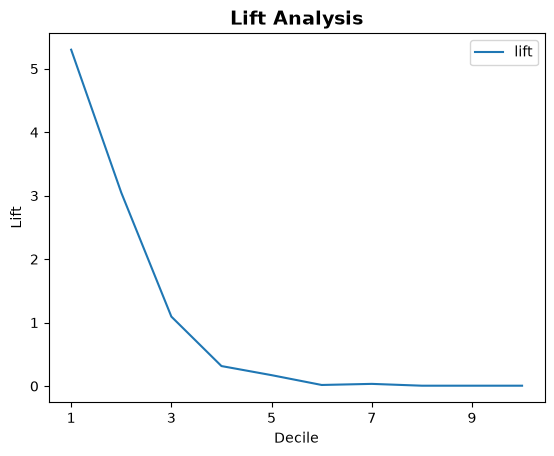

In [7]:
lift_table = decile_table[[
    'decile', 'cumulative_population_percentage', 'customers',
    'subscribers', 'lift'    
]]

display(
    lift_table.
    style.
    format({
            'customers':'{:,}',
            'cumulative_population_percentage':'{:.0f}%',
            'subscribers':'{:,}',
            'lift':'{:.2f}'
        }).
    hide(axis='index')
)

# Visualize lift chart
plt.figure(figsize=(10, 6))
lift_table.plot(
    x='decile',
    y='lift'
)
plt.title("Lift Analysis", fontdict={'size':14, 'weight':'bold'})
plt.xlabel("Decile")
plt.ylabel("Lift")
display_md("**At the top 20% of customers, the model achieves a cumulative lift of 3.05. This indicates that the selected customer group is approximately 3.05 times more likely to contain subscribers compared with randomly selected customers.**")
plt.show()



## **4. Baseline vs Top-10% ROI**

The improvement from targeting the top 10% is

__Efficiency Lift = Profit Per Customer (Top 10%) / Profit Per Customer (baseline)__

where, Profit Per Customer = Net Profit / Total Customers

In [8]:
decile_table.columns

Index(['decile', 'customers', 'subscribers', 'avg_probability',
       'conversion_rate', 'cumulative_subscribers', 'cumulative_gain',
       'population_percentage', 'cumulative_population_percentage', 'lift'],
      dtype='object')

In [11]:
df['actual_values'].mean() * len(df)

1745.0

In [16]:
# Business assumptions
revenue_per_conversion = 20
cost_per_contact = 2

metric = {}
# -----------------------------
# Overall Campaign
# -----------------------------

total_customers = len(df)

overall_conversion_rate = df["actual_values"].mean()

overall_conversions = (
    total_customers * overall_conversion_rate
)

overall_revenue = (
    overall_conversions * revenue_per_conversion
)

overall_cost = (
    total_customers * cost_per_contact
)

overall_net_profit = (
    overall_revenue - overall_cost
)

overall_roi = (
    (overall_revenue - overall_cost)
    / overall_cost
) * 100

# Profit Efficiency: compare the net profit generated per customer contacted
overall_profit_efficiency = (
    overall_net_profit / (total_customers)
)

metric['Overall campaign'] = {
    "Customers Contacted": total_customers,
    "Conversion Rate": overall_conversion_rate * 100,
    "Expected Conversions": overall_conversions,
    "Revenue": overall_revenue,
    "Campaign Cost": overall_cost,
    "Net Profit": overall_net_profit,
    "Net Profit Per Customers": overall_profit_efficiency,
    "Efficiency Lift": '—',
    "ROI (%)": overall_roi
}

# -----------------------------
# Top 10% Campaign
# -----------------------------

top_10_customers = (
    decile_table.loc[
        decile_table['decile']==1,
        'customers'
    ].iloc[0]
)

# Conversion rate of Decile 1
top_10_conversion_rate = (
    decile_table.loc[
        decile_table["decile"] == 1,
        "conversion_rate"
    ].iloc[0]/100
)

top_10_conversions = (
    decile_table.loc[
        decile_table['decile']==1,
        'subscribers'
    ].iloc[0]
)

top_10_revenue = (
    top_10_conversions * revenue_per_conversion
)

top_10_cost = (
    top_10_customers * cost_per_contact
)

top_10_net_profit = (
    top_10_revenue - top_10_cost
)

top_10_profit_efficiency = (
    top_10_net_profit / (top_10_customers)
)

top_10_roi = (
    (top_10_revenue - top_10_cost)
    / top_10_cost
) * 100

efficiency_lift = (
    top_10_profit_efficiency / overall_profit_efficiency
)

metric['Top 10% campaign'] = {
    "Customers Contacted": top_10_customers,
    "Conversion Rate": top_10_conversion_rate * 100,
    "Expected Conversions": top_10_conversions,
    "Revenue": top_10_revenue,
    "Campaign Cost": top_10_cost,
    "Net Profit": top_10_net_profit,
    "Net Profit Per Customers": top_10_profit_efficiency,
    "Efficiency Lift": efficiency_lift,
    "ROI (%)": top_10_roi
}

# -----------------------------
# Comparison
# -----------------------------


comparison = pd.DataFrame(metric)
pd.set_option('display.float_format', "{:.1f}".format)
profit_improvement = top_10_net_profit/overall_net_profit
display_md(f"**Top-10% targeting strategy generates approximately {profit_improvement:.2f} x higher profit per contacted customer than the baseline strategy.**")
display(comparison)



**Top-10% targeting strategy generates approximately 3.07 x higher profit per contacted customer than the baseline strategy.**

,Overall campaign,Top 10% campaign
Customers Contacted,14919,1492.0
Conversion Rate,11.7,62.0
Expected Conversions,1745.0,925.0
Revenue,34900.0,18500.0
Campaign Cost,29838,2984.0
Net Profit,5062.0,15516.0
Net Profit Per Customers,0.3,10.4
Efficiency Lift,—,30.6
ROI (%),17.0,520.0


| Metric | Call all 14,919 Leads | Call Top 10% ~ 1,492 Leads |
|--------|------------------:|------------------:|
| Total Customers Contacted | 14,919 | 1,492 |
| Conversion Rate | 11.7% (baseline) | 62% (~ 5 x higher than baseline) |
| Successful Subscriptions | 1,745 | 925 |
| Revenue per Subscription | $20 | $20 |
| Total Revenue | $34,900 | $18,500 |
| Campaign Cost (@ $2/contact) | $29,838 | $2,984 |
| Net Profit | $5,062 | $15,516 |
| Cost Reduction vs. Calling All | — | ~ 90% fewer calls |
| Profit Improvement vs. Calling All | — | ~ 3 x higher net profit |


## **5. Project Highlights**

| Analysis             | Main question                                            |
| -------------------- | -------------------------------------------------------- |
| **Decile analysis**  | Does the model rank customers effectively?               |
| **Gain**             | How many responders do I capture by targeting X%?        |
| **Lift**             | How much better is targeting X% than random?             |
| **Baseline vs Top-10% ROI**             | How many times more profitable is targeting the top 10% compared with the baseline strategy?             |
| **Calibration plot** | Are the predicted probabilities numerically trustworthy? |
| **Brier score**      | How accurate are the predicted probabilities overall?    |
| **Bootstrap CI**     | How certain are my decile/lift estimates?                |


In [22]:
decile_table

,decile,customers,subscribers,avg_probability,conversion_rate,cumulative_subscribers,cumulative_gain,population_percentage,cumulative_population_percentage,lift
0,1,1492,925.0,92.2,62.0,925.0,53.0,10.0,10.0,5.3
1,2,1492,532.0,71.7,35.7,1457.0,83.5,10.0,20.0,3.0
2,3,1492,191.0,41.1,12.8,1648.0,94.4,10.0,30.0,1.1
3,4,1492,55.0,18.2,3.7,1703.0,97.6,10.0,40.0,0.3
4,5,1492,30.0,7.8,2.0,1733.0,99.3,10.0,50.0,0.2
5,6,1491,3.0,3.6,0.2,1736.0,99.5,10.0,60.0,0.0
6,7,1492,6.0,1.8,0.4,1742.0,99.8,10.0,70.0,0.0
7,8,1492,1.0,0.8,0.1,1743.0,99.9,10.0,80.0,0.0
8,9,1492,1.0,0.3,0.1,1744.0,99.9,10.0,90.0,0.0
9,10,1492,1.0,0.1,0.1,1745.0,100.0,10.0,100.0,0.0


In [ ]:
pl.plot(
    
)

In [ ]:
cum_cust = np.arange(1, len(df)+1)/len(df)

array([6.70286212e-05, 1.34057242e-04, 2.01085864e-04, ...,
       9.99865943e-01, 9.99932971e-01, 1.00000000e+00])

In [28]:
cum_subs = df['actual_values'].cumsum()/df['actual_values'].sum()

In [29]:
decile_table

,decile,customers,subscribers,avg_probability,conversion_rate,cumulative_subscribers,cumulative_gain,population_percentage,cumulative_population_percentage,lift
0,1,1492,925.0,92.2,62.0,925.0,53.0,10.0,10.0,5.3
1,2,1492,532.0,71.7,35.7,1457.0,83.5,10.0,20.0,3.0
2,3,1492,191.0,41.1,12.8,1648.0,94.4,10.0,30.0,1.1
3,4,1492,55.0,18.2,3.7,1703.0,97.6,10.0,40.0,0.3
4,5,1492,30.0,7.8,2.0,1733.0,99.3,10.0,50.0,0.2
5,6,1491,3.0,3.6,0.2,1736.0,99.5,10.0,60.0,0.0
6,7,1492,6.0,1.8,0.4,1742.0,99.8,10.0,70.0,0.0
7,8,1492,1.0,0.8,0.1,1743.0,99.9,10.0,80.0,0.0
8,9,1492,1.0,0.3,0.1,1744.0,99.9,10.0,90.0,0.0
9,10,1492,1.0,0.1,0.1,1745.0,100.0,10.0,100.0,0.0


In [43]:
cum_sub = (100 * decile_table['cumulative_subscribers']/decile_table['subscribers'].sum())#.cumsum())
cum_sub

0    53.0
1    83.5
2    94.4
3    97.6
4    99.3
5    99.5
6    99.8
7    99.9
8    99.9
9   100.0
Name: cumulative_subscribers, dtype: float64

In [40]:
cum_cust = 100 * decile_table['customers'].cumsum()/len(df)
decile_table['cumulative_subscribers']

0    925.0
1   1457.0
2   1648.0
3   1703.0
4   1733.0
5   1736.0
6   1742.0
7   1743.0
8   1744.0
9   1745.0
Name: cumulative_subscribers, dtype: float64

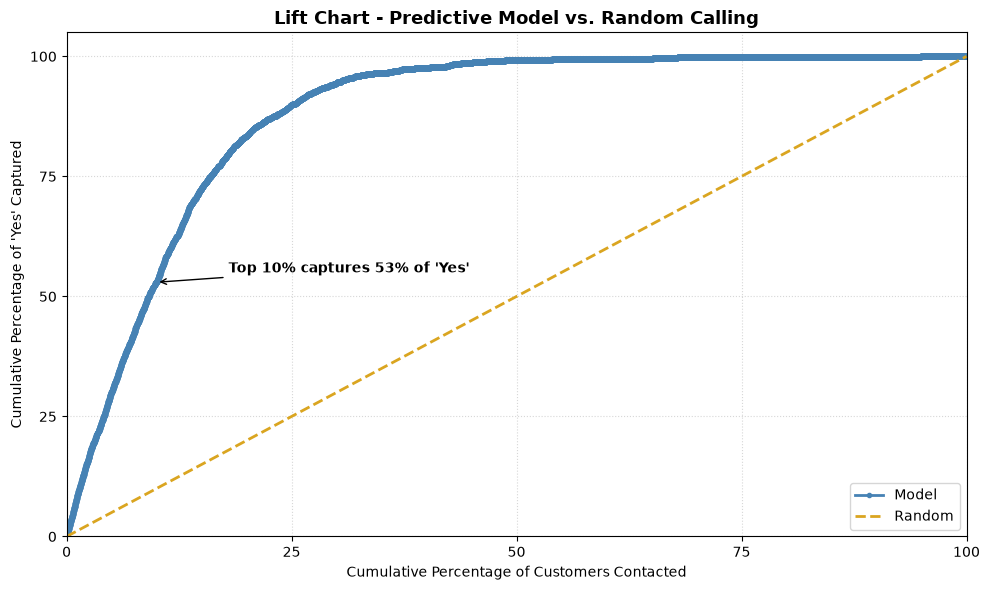

In [48]:
# 9. Sort customers by predicted probability
results = pd.DataFrame({
    "Actual": y_test.values,
    "Probability": predicted_proba
})

results = results.sort_values(
    "Probability", ascending=False
).reset_index(drop=True)

# 10. Calculate cumulative percentage of Yes captured
total_yes = results["Actual"].sum()

results["Cumulative_Yes"] = results["Actual"].cumsum()

results["Cumulative_Yes_Percentage"] = (
    results["Cumulative_Yes"] / total_yes
)

# 11. Calculate cumulative percentage of customers contacted
results["Cumulative_Customers"] = (
    np.arange(1, len(results) + 1) / len(results)
)

# Add starting point (0,0)
x = np.insert(
    results["Cumulative_Customers"].values * 100,
    0, 0
)

y_model = np.insert(
    results["Cumulative_Yes_Percentage"].values * 100,
    0, 0
)

# 12. Plot lift / cumulative gains chart
plt.figure(figsize=(10, 6))

plt.plot(
    x, y_model,
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=2,
    label="Model"
)

# Random calling baseline
plt.plot(
    [0, 100], [0, 100],
    color="goldenrod",
    linestyle="--",
    linewidth=2,
    label="Random"
)

# Highlight top 10%
top_10 = np.searchsorted(x, 10, side="right") - 1
top_10 = max(0, top_10)

capture_10 = y_model[top_10]

plt.annotate(
    f"Top 10% captures {capture_10:.0f}% of 'Yes'",
    xy=(x[top_10], capture_10),
    xytext=(18, 55),
    arrowprops=dict(arrowstyle="->", color="black"),
    fontsize=10,
    fontweight="bold"
)

# Formatting
plt.xlabel("Cumulative Percentage of Customers Contacted")
plt.ylabel("Cumulative Percentage of 'Yes' Captured")

plt.title(
    "Lift Chart - Predictive Model vs. Random Calling",
    fontsize=13,
    fontweight="bold"
)

plt.xlim(0, 100)
plt.ylim(0, 105)

plt.xticks(np.arange(0, 101, 25))
plt.yticks(np.arange(0, 101, 25))

plt.grid(True, linestyle=":", alpha=0.5)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()
